# 06 - From Logistic Regression to Scorecard

**Goal:** translate the WoE logistic regression into a **scorecard**: a table of fixed points per bin that anyone can add up. This notebook uses the **development set only**;
the hold-out set is first opened in notebook 07.

**PDO scaling**

| Parameter | Value | Meaning |
|---|---|---|
| Base score | 600 | score at the base odds |
| Base odds | 50 : 1 (good : bad) | PD = 1/51 = 1.96% at the base score |
| PDO | 20 | every +20 points doubles the odds of good |

Formulas: `Factor = PDO / ln 2`, `Offset = BaseScore - Factor x ln(BaseOdds)`, `Score = Offset + Factor x ln(odds good:bad)`.

The model gives log-odds of **bad**, `z = b0 + sum(b_i x WoE_i)`, so `ln(odds good:bad) = -z` and

`Score = Offset - Factor x z = sum_i [ -Factor x b_i x WoE_i + (Offset - Factor x b0) / n ]`

Each bin therefore has fixed points, and the intercept part is spread equally over the `n` variables (a common convention). Points are rounded to integers.

In [1]:
import sys, json
sys.path.insert(0, "../src")

from pathlib import Path
for _p in ("../data/processed", "../outputs/figures", "../outputs/metrics", "../outputs/scorecard"):
    Path(_p).mkdir(parents=True, exist_ok=True)   # Git does not keep empty folders

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from feature_engineering import WoEBinner
from scorecard import Scorecard, scaling_params, score_to_pd
from evaluation import discrimination_metrics

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

BASE_SCORE, BASE_ODDS, PDO = 600, 50, 20
factor, offset = scaling_params(BASE_SCORE, BASE_ODDS, PDO)
print(f"Factor = {factor:.4f} | Offset = {offset:.4f}")

dev = pd.read_csv("../data/processed/dev.csv", index_col="id")
y = dev["target"]
binners = {v: WoEBinner.from_dict(s) for v, s in json.load(open("../outputs/scorecard/binning_spec.json")).items()}
model = json.load(open("../outputs/scorecard/model_spec.json"))
bin_tables = pd.read_csv("../outputs/scorecard/woe_bin_tables.csv")
print("Variables in the scorecard:", list(model["coefficients"]))

Factor = 28.8539 | Offset = 487.1229
Variables in the scorecard: ['revolving_util', 'age', 'n_30_59_late', 'n_60_89_late', 'n_90_late', 'debt_ratio', 'n_open_lines', 'n_real_estate', 'n_dependents']


## 1. Check the scaling

In [2]:
chk = pd.DataFrame({"odds good:bad": [25, 50, 100, 200]})
chk["score"] = offset + factor * np.log(chk["odds good:bad"])
chk["PD"] = 1 / (1 + chk["odds good:bad"])
chk.round(4)

,odds good:bad,score,PD
0,25,580.0,0.0385
1,50,600.0,0.0196
2,100,620.0,0.0099
3,200,640.0,0.0050


Score is 600 at odds 50:1, 620 at 100:1 (odds doubled, +20 points = PDO) and 580 at 25:1. The PD column is `1 / (1 + odds)`.

## 2. Build the scorecard

In [3]:
card = Scorecard(binners, model["intercept"], model["coefficients"], factor, offset, round_points=True)
exact = Scorecard(binners, model["intercept"], model["coefficients"], factor, offset, round_points=False)
print(f"Base points per variable = (Offset - Factor x intercept) / n = {card.base_points:.2f}")
points = card.points_table(bin_tables)
for v in card.binners:
    print(f"\n{v}")
    display(points[points.variable == v].drop(columns=["variable", "coef"]).round(4))

Base points per variable = (Offset - Factor x intercept) / n = 62.48

revolving_util


,bin,rows,pct_rows,bad_rate,woe,points
0,<= 0.06019,36684,0.3494,0.0171,1.4128,87.0
1,"(0.06019, 0.132]",13102,0.1248,0.0218,1.1702,83.0
2,"(0.132, 0.3065]",15721,0.1497,0.0354,0.6701,74.0
3,"(0.3065, 0.4989] or Missing",10656,0.1015,0.0572,0.1673,65.0
4,"(0.4989, 0.6933]",7861,0.0749,0.0966,-0.3997,56.0
5,"(0.6933, 0.8491]",5241,0.0499,0.1414,-0.8320,48.0
6,"(0.8491, 1]",13563,0.1292,0.1921,-1.1997,42.0
7,> 1,2159,0.0206,0.3868,-2.1749,25.0



age


,bin,rows,pct_rows,bad_rate,woe,points
8,21-29,6125,0.0583,0.1169,-0.6137,55.0
9,30-36,10569,0.1007,0.1055,-0.4983,57.0
10,37-43,14309,0.1363,0.0930,-0.3585,58.0
11,44-54,28026,0.2669,0.0777,-0.1625,61.0
12,55-57,7254,0.0691,0.0573,0.1637,64.0
13,58-62,12031,0.1146,0.0460,0.3970,67.0
14,63-66,8374,0.0798,0.0345,0.6955,71.0
15,67+,18299,0.1743,0.0230,1.1128,76.0



n_30_59_late


...

,bin,rows,pct_rows,bad_rate,woe,points
35,0-1,4397,0.0419,0.1733,-1.0734,59.0
36,2,4738,0.0451,0.0927,-0.3542,61.0
37,3,6327,0.0603,0.0789,-0.1780,62.0
38,4-5,17070,0.1626,0.0634,0.0572,63.0
39,6+,72455,0.6901,0.0585,0.1427,63.0



n_real_estate


,bin,rows,pct_rows,bad_rate,woe,points
40,0,39425,0.3755,0.0834,-0.2392,58.0
41,1,36618,0.3488,0.0524,0.2590,67.0
42,2,21975,0.2093,0.0564,0.1808,66.0
43,3,4431,0.0422,0.0639,0.0491,63.0
44,4+,2538,0.0242,0.1139,-0.5841,51.0



n_dependents


,bin,rows,pct_rows,bad_rate,woe,points
45,0,60916,0.5802,0.0581,0.1499,63.0
46,1,18454,0.1758,0.0753,-0.1282,62.0
47,2,13557,0.1291,0.0806,-0.2019,61.0
48,3,6624,0.0631,0.0904,-0.3275,60.0
49,4+,2713,0.0258,0.1014,-0.4537,59.0
50,Missing,2723,0.0259,0.0455,0.4067,65.0


**Reading:** the bigger the points, the safer the bin. For example `revolving_util <= 0.06` earns far more points than `> 1`. The point differences across bins of a variable
(not the absolute points) tell you how much that variable can move a customer's score.

## 3. Consistency checks on the development set

In [4]:
s_round = card.score(dev)
s_exact = exact.score(dev)
err = (s_round - s_exact).abs()
print(f"Rounding error vs exact points: mean absolute = {err.mean():.2f}, max = {err.max():.2f}, "
      f"mean signed (rounded - exact) = {(s_round - s_exact).mean():+.2f} points")
print(f"Mean PD implied by the ROUNDED score = {score_to_pd(s_round, factor, offset).mean():.4%}")

# the exact score must equal the scaled log-odds of the logistic regression
X = pd.DataFrame({v: binners[v].transform(dev[v]) for v in model["coefficients"]})
z = model["intercept"] + sum(model["coefficients"][v] * X[v] for v in X)
assert np.allclose(s_exact, offset - factor * z)
print("OK: exact score = Offset - Factor x log-odds of the model")

pd_model = 1 / (1 + np.exp(-z))
pd_score = pd.Series(score_to_pd(s_exact, factor, offset), index=dev.index)
assert np.allclose(pd_model, pd_score)
print(f"OK: PD implied by the score equals the model PD. Mean PD = {pd_score.mean():.4%} | bad rate = {y.mean():.4%}")

Rounding error vs exact points: mean absolute = 1.05, max = 3.34, mean signed (rounded - exact) = +1.01 points
Mean PD implied by the ROUNDED score = 6.5408%


OK: exact score = Offset - Factor x log-odds of the model


OK: PD implied by the score equals the model PD. Mean PD = 6.6865% | bad rate = 6.6865%


The rounding error is about one point on average and never above ~3-4 points, which is small next to a 20-point PDO.
It is **not symmetric**, though: most customers sit in the same large bins (e.g. no delinquency), whose points happen to be rounded up, so the
rounded score is on average about **1 point higher** than the exact one. That raises the odds of good by about 3.5% and lowers the mean
score-implied PD on development from 6.69% to about 6.54%. Notebook 07 validates the **rounded** scorecard (what would be used in practice), so this
small optimism is visible in its overall calibration figures.

## 4. Hand check: add up the points of one customer

In [5]:
i = dev.index[0]
parts = []
for v, b in binners.items():
    if v in card.coefs:
        idx = int(b.bin_index(dev.loc[[i], v]).iloc[0])
        parts.append({"variable": v, "value": dev.loc[i, v], "bin_index": idx, "points": card.points[v][idx]})
parts = pd.DataFrame(parts)
display(parts)
print("Sum of points =", parts["points"].sum(), "| card.score() =", s_round.loc[i])
assert parts["points"].sum() == s_round.loc[i]

,variable,value,bin_index,points
0,revolving_util,0.957151,6,42.0
1,age,40.000000,2,58.0
2,n_30_59_late,0.000000,0,70.0
3,n_60_89_late,0.000000,0,66.0
4,n_90_late,0.000000,0,69.0
5,debt_ratio,0.121876,1,65.0
6,n_open_lines,4.000000,3,63.0
7,n_real_estate,0.000000,0,58.0
8,n_dependents,1.000000,1,62.0


Sum of points = 553.0 | card.score() = 553.0


## 5. Score distribution

count    104987.0
mean        583.8
std          34.7
min         390.0
25%         566.0
50%         592.0
75%         609.0
max         632.0
dtype: float64
Score range possible: (363.0, 634.0)


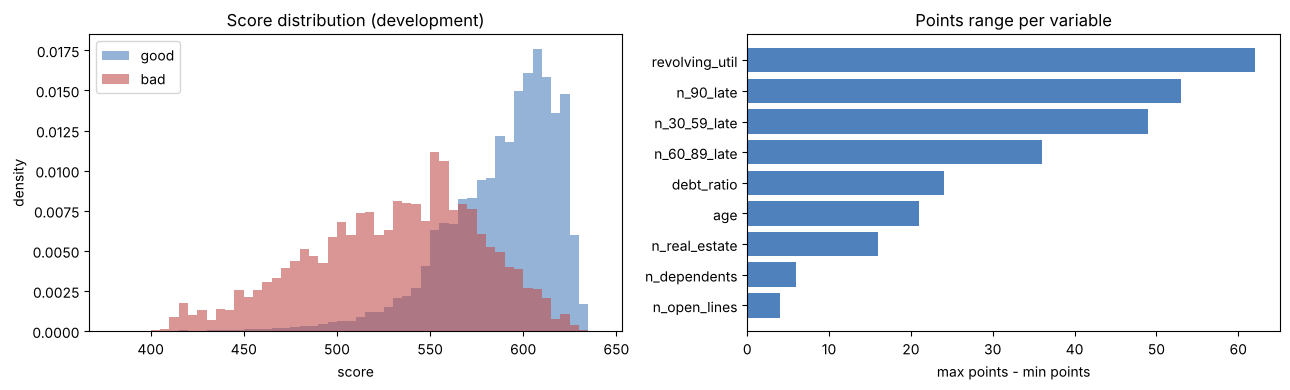

revolving_util    62.0
n_90_late         53.0
n_30_59_late      49.0
n_60_89_late      36.0
debt_ratio        24.0
age               21.0
n_real_estate     16.0
n_dependents       6.0
n_open_lines       4.0
dtype: float64

In [6]:
print(s_round.describe().round(1))
print("Score range possible:", card.score_range())

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
bins = np.arange(380, 641, 5)
ax[0].hist(s_round[y == 0], bins=bins, density=True, alpha=0.6, label="good", color="#4f81bd")
ax[0].hist(s_round[y == 1], bins=bins, density=True, alpha=0.6, label="bad", color="#c0504d")
ax[0].set_xlabel("score"); ax[0].set_ylabel("density"); ax[0].legend(); ax[0].set_title("Score distribution (development)")

rng_pts = pd.Series({v: card.points[v].max() - card.points[v].min() for v in card.coefs}).sort_values()
ax[1].barh(rng_pts.index, rng_pts.values, color="#4f81bd")
ax[1].set_xlabel("max points - min points"); ax[1].set_title("Points range per variable")
plt.tight_layout(); plt.savefig("../outputs/figures/score_distribution_and_points_range.png", dpi=130); plt.show()
rng_pts.sort_values(ascending=False).round(0)

**Reading:** bad customers sit clearly to the left of good ones, and most customers score between roughly 560 and 630 (a long left tail contains the risky ones).
The points-range chart shows which variables can move the score most: it broadly follows the IV ranking (`revolving_util` and the delinquency counts dominate), but not exactly, because points also depend on the coefficients (e.g. `n_open_lines` has a higher IV than `debt_ratio` but the smallest range).

## 6. Save the scorecard

In [7]:
points.to_csv("../outputs/scorecard/scorecard_points.csv", index=False)
scorecard_spec = {
    "base_score": BASE_SCORE, "base_odds_good_to_bad": BASE_ODDS, "pdo": PDO,
    "factor": factor, "offset": offset, "intercept": model["intercept"],
    "n_variables": len(card.coefs), "base_points_per_variable": card.base_points,
    "round_points": True, "coefficients": model["coefficients"],
}
with open("../outputs/scorecard/scorecard_spec.json", "w") as f:
    json.dump(scorecard_spec, f, indent=2)
print("Saved scorecard_points.csv and scorecard_spec.json")

Saved scorecard_points.csv and scorecard_spec.json


## Summary

- Scaling: 600 points at odds 50:1, PDO = 20 (Factor = 28.85, Offset = 487.12).
- 9 variables, 62.5 base points each plus the bin points; scores on the development set range from about 390 to 632 with a median of 592.
- Points reproduce the model: the exact score equals the scaled log-odds, and the integer rounding costs about 1 point on average.
- The hold-out set is still unopened.

**Questions to answer in your own words (interview material)**
1. What does "PDO = 20" mean in plain words, and what happens to the PD when the score rises by 20 points?
2. Why is the intercept spread over the variables instead of listed as a separate line?
3. Why does the unrounded scorecard give exactly the same ranking as the logistic regression, and why does rounding change it only slightly?

Next: notebook 07 - **validation on the hold-out set**: AUC, Gini, KS with confidence intervals, rank ordering by grade, calibration, and the cut-off table.